In [36]:
# =========================
# Student Exam Score Predictor (1000 rows dataset)
# =========================

# 1. Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [37]:
# 2. Load Dataset
data = pd.read_csv("student_scores.csv")
print("Dataset loaded successfully!")
print(data.shape)   # should show (1000, 5)
print(data.head())

# 3. Train/Test Split
X = data[['Hours', 'Attendance', 'Sleep', 'Assignments']]   # Features
y = data['Scores']                                          # Target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Train/test split completed successfully!")

Dataset loaded successfully!
(1000, 5)
   Hours  Attendance  Sleep  Assignments  Scores
0   4.37       59.26      7            8   75.64
1   9.56       77.10      6            6  110.03
2   7.59       93.65      7            1   87.81
3   6.39       86.61      9            4   90.30
4   2.40       90.33      5            7   72.71
Train/test split completed successfully!


In [38]:
# 4. Build Pipeline (Scaling + Regression)
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('regressor', LinearRegression())
])

# Train pipeline
pipeline.fit(X_train, y_train)
print("Pipeline trained successfully!")

# Predictions
y_pred = pipeline.predict(X_test)
print("Predictions made successfully!")
print('Predicted Scores:', y_pred)
print('---------------- Actual Scores -------------------')
print('Actual Scores:   ', list(y_test))

# 5. Model Evaluation
print("Evaluation Metrics (Linear Regression):")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

Pipeline trained successfully!
Predictions made successfully!
Predicted Scores: [ 73.26059759  94.90110262  72.168835    68.0244301  106.76104625
  97.29325798  76.45895089  94.37270003  74.36635057  68.87452177
 111.90360819  80.51659688  73.75143326  69.29404313  60.63458137
  71.85683512  92.38210904  54.7622293   78.08328938  65.71209404
  78.2105796   76.35626442  63.23599317  57.33580055  74.93385999
  73.73995517  93.35053545  85.26892826  72.37696781  92.08233422
  96.04485208  86.71976202  71.24923285  98.31797671  80.60047543
 104.47268316  78.42859654  77.41504145  65.17993613  82.71609526
  78.57456648  79.07385431  59.15393558  43.7950934   79.66282614
  84.41493597  64.87629926  54.71567657  69.92321953  83.41945266
  69.61591308  61.80111874  93.87725655  74.01093037  61.82538126
  72.69216321  86.9067132   49.54225546  74.2474317  105.81171419
  86.88292571  80.67490099  63.67358458  90.80488175  45.4810837
  65.19989858 107.95219252  67.37863771  88.57266089  88.100967

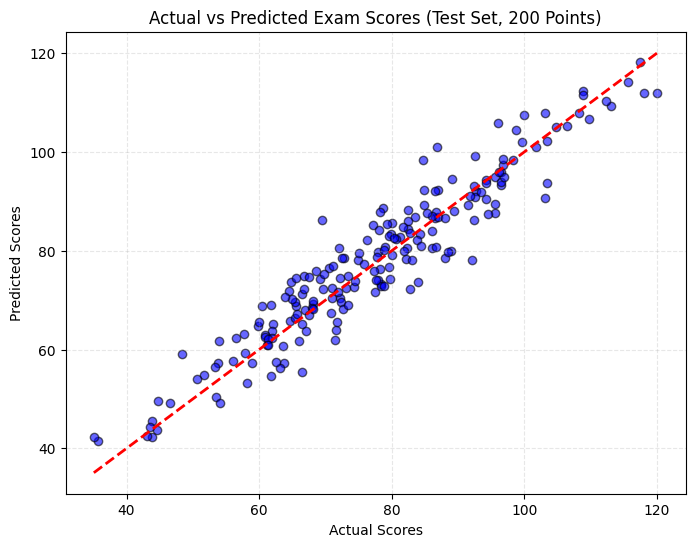

In [39]:
# 6. Visualization (Test Set, 200 Points)
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, color='blue', alpha=0.6, edgecolors='black')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)
plt.xlabel("Actual Scores")
plt.ylabel("Predicted Scores")
plt.title("Actual vs Predicted Exam Scores (Test Set, 200 Points)")
plt.grid(True, alpha=0.3, linestyle='--')
plt.show()

Best Parameters: {'regressor': Ridge(), 'regressor__alpha': 1.0}
Evaluation Metrics (Best Model):
MAE: 4.051165004212979
MSE: 26.72079221455133
R2 Score: 0.9045241624056723


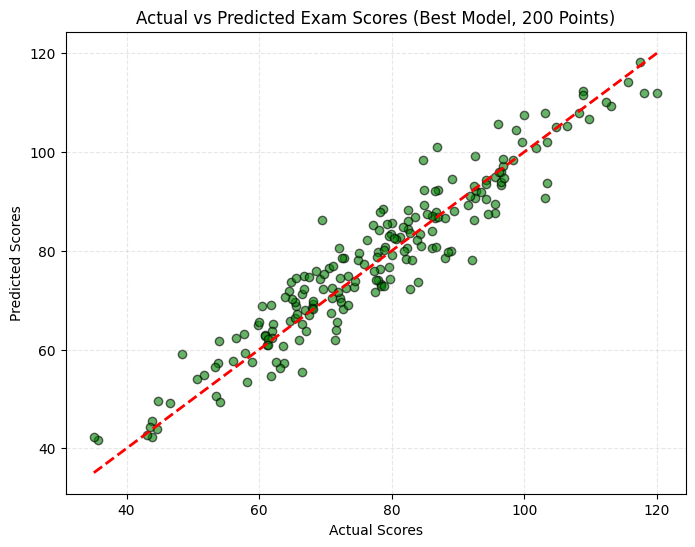

In [40]:
# 7. Hyperparameter Tuning with GridSearchCV
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('regressor', Ridge())
])

# Define hyperparameter grid as list of dicts for multiple models
param_grid = [
    {
        'regressor': [LinearRegression()],
    },
    {
        'regressor': [Ridge(), Lasso()],
        'regressor__alpha': [0.1, 1.0, 10.0]
    }
]

# Create GridSearchCV with the correct param_grid
grid_search = GridSearchCV(pipeline, param_grid, cv=5, scoring='r2')
grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
best_model = grid_search.best_estimator_

# Predictions with best model
y_pred_best = best_model.predict(X_test)

# Final Evaluation
print("Evaluation Metrics (Best Model):")
print("MAE:", mean_absolute_error(y_test, y_pred_best))
print("MSE:", mean_squared_error(y_test, y_pred_best))
print("R2 Score:", r2_score(y_test, y_pred_best))

# 8. Visualization (Best Model)
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_best, color='green', alpha=0.6, edgecolors='black')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)
plt.xlabel("Actual Scores")
plt.ylabel("Predicted Scores")
plt.title("Actual vs Predicted Exam Scores (Best Model, 200 Points)")
plt.grid(True, alpha=0.3, linestyle='--')
plt.show()

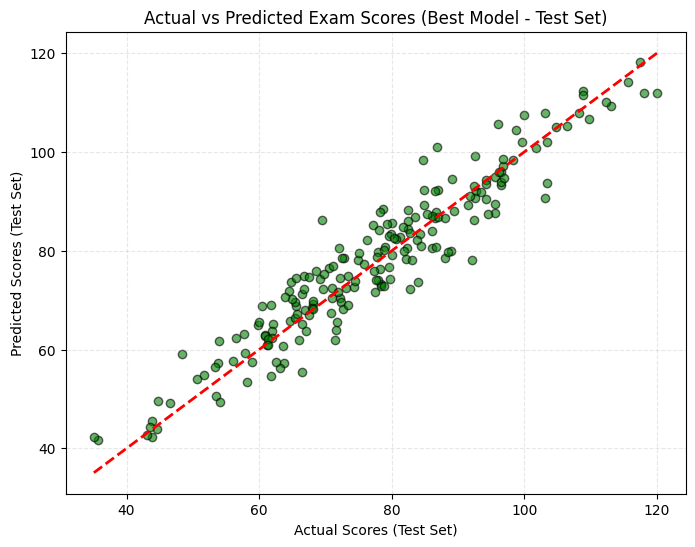

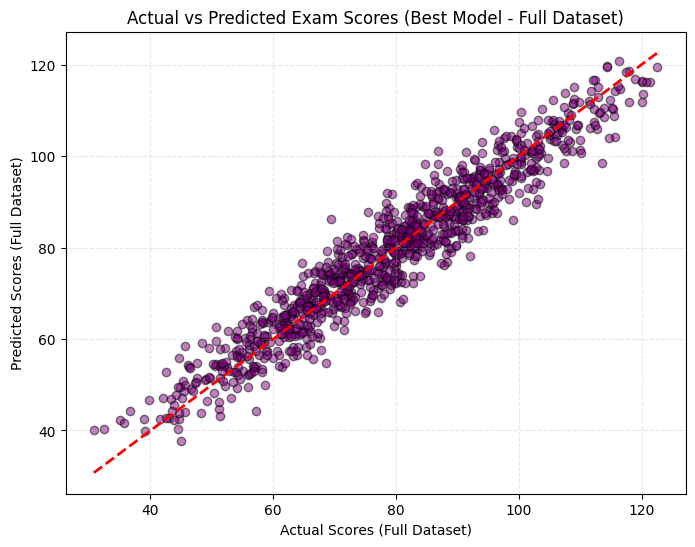

In [41]:
# =========================
# 9. Dual Visualization Setup
# =========================

# Test Set Visualization (200 points)
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_best, color='green', alpha=0.6, edgecolors='black')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)
plt.xlabel("Actual Scores (Test Set)")
plt.ylabel("Predicted Scores (Test Set)")
plt.title("Actual vs Predicted Exam Scores (Best Model - Test Set)")
plt.grid(True, alpha=0.3, linestyle='--')
plt.show()

# Full Dataset Visualization (1000 points)
plt.figure(figsize=(8, 6))
plt.scatter(y, best_model.predict(X), color='purple', alpha=0.5, edgecolors='black')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', linewidth=2)
plt.xlabel("Actual Scores (Full Dataset)")
plt.ylabel("Predicted Scores (Full Dataset)")
plt.title("Actual vs Predicted Exam Scores (Best Model - Full Dataset)")
plt.grid(True, alpha=0.3, linestyle='--')
plt.show()
